# Who Should the Bank Call?
### Capstone: targeting a term-deposit telemarketing campaign with machine learning

**The business problem.** A Portuguese bank sells term deposits by phone. Calling everyone is expensive: most customers say no, and every call costs agent time. The bank wants to know **which customers to call first**, and **how many calls are worth making**.

**The data.** 41,188 calls from May 2008 to November 2010, with customer details, the outcome of earlier campaigns, and the state of the economy. Source: the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing) (CC BY 4.0, citation in [README.md](README.md)).

**The plan:** data audit → exploration → statistics → models → business value → explanation. The model is then used in an interactive app ([app.py](app.py)).

This project uses every part of the repo: Python and modules (Part 1), pandas, visualisation, statistics, EDA and machine learning (Part 2).

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OrdinalEncoder

import bank_model as bm   # data loading, features and the model, shared with app.py and the tests

sys.path.insert(0, "../13_visualisation")
import chart_style as cs

cs.apply()
pd.set_option("display.max_columns", 25)

# 1. Define success first

Before touching the data, decide how we'll judge the result. **The bank doesn't need a perfect prediction for each customer; it needs a good *ranking*.** If we call the most promising customers first, how many sales do we get for each call?

| Metric | Question it answers |
|--------|---------------------|
| **Precision at top 20%** | If we call our best 20% of customers, what share of calls end in a sale? |
| **Lift** | How many times better than calling at random? |
| **ROC AUC** | How well does the model rank yes above no overall? (0.5 = random, 1 = perfect) |
| **Profit** | Sales × value − calls × cost. The number the business actually cares about |

We won't use **accuracy**: only ~11% of customers say yes, so a model that predicts "no" for everyone is 89% accurate and completely useless.

# 2. Data audit

In [2]:
raw = pd.read_csv(bm.DATA_FILE, sep=";")
print(raw.shape)
print("exact duplicate rows:", raw.duplicated().sum())
raw.head()

(41188, 21)
exact duplicate rows: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df = bm.load_data()   # drops the duplicates and adds our engineered features
print(df.shape)
print(f"subscribed: {df['subscribed'].mean():.1%} of calls")

(41176, 24)
subscribed: 11.3% of calls


## 2.1 Hidden missing values

There are no empty cells, but the documentation says missing values are written as `"unknown"`, and `pdays = 999` means "never contacted before". **Missing data often hides behind placeholder values.**

In [4]:
unknown = (df[["job", "marital", "education", "default", "housing", "loan"]] == "unknown").sum()
print(unknown.to_string())
print(f"\npdays == 999 (never contacted before): {(df['pdays'] == 999).mean():.1%} of rows")
print("customers with a credit default = 'yes':", (df["default"] == "yes").sum())

job           330
marital        80
education    1730
default      8596
housing       990
loan          990

pdays == 999 (never contacted before): 96.3% of rows
customers with a credit default = 'yes': 3


- `default` is "unknown" for about a fifth of customers, and only **3** customers have a confirmed default. That column says more about *what the bank recorded* than about the customer, so we keep "unknown" as its own category instead of guessing.
- `pdays = 999` for 96% of rows. As a number, 999 would look like "contacted a very long time ago". We replace it with a clear yes/no feature, `contacted_before` (see [bank_model.py](bank_model.py)).

## 2.2 Leakage: columns we must not use

The documentation warns that **`duration`** (call length) is only known *after* the call, and a 0-second call is always a "no". **`campaign`** counts contacts in this campaign *including the last one*, so it's also only complete after the fact. Here's how tempting `duration` looks:

In [5]:
print(df.groupby("y")["duration"].mean().round(0).rename("average call length (seconds)").to_string())

y
no     221.0
yes    553.0


Long calls go with sales, because people who are interested stay on the phone. But when we're deciding *whom to call*, the call hasn't happened yet. Both columns are excluded from the model (`bank_model.LEAKY`). In section 5 we'll measure how much they would fake the results.

## 2.3 The world changed during the data

The rows are in date order. Let's look at the success rate along that order:

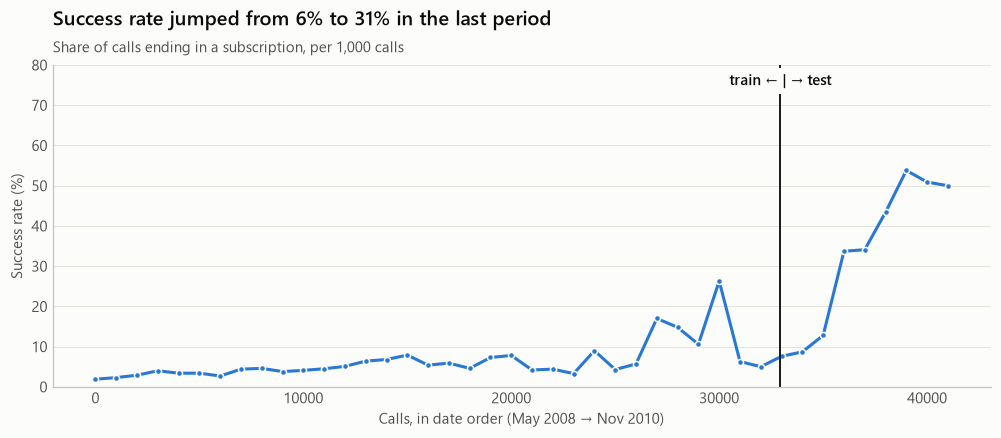

employment level (nr.employed), train: 5099.1 to 5228.1
employment level (nr.employed), test:  4963.6 to 5099.1


In [6]:
train, test = bm.split_by_time(df)
chunk = 1000
rate = df["subscribed"].groupby(df.index // chunk).mean()

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(rate.index * chunk, rate.values * 100, color=cs.PRIMARY, marker="o", markersize=4,
        markeredgecolor=cs.SURFACE, markeredgewidth=1)
ax.axvline(len(train), color=cs.INK, linewidth=1.2)
ax.annotate("train ← | → test", (len(train), 75), ha="center", fontweight="semibold",
            backgroundcolor=cs.SURFACE)
ax.set_ylim(0, 80)
ax.set(xlabel="Calls, in date order (May 2008 → Nov 2010)", ylabel="Success rate (%)")
cs.only_grid(ax, "y")
cs.title(ax, f"Success rate jumped from {train['subscribed'].mean():.0%} to {test['subscribed'].mean():.0%} in the last period",
         "Share of calls ending in a subscription, per 1,000 calls")
fig.savefig("images/time_shift.png")
plt.show()

print("employment level (nr.employed), train:", train["nr.employed"].min(), "to", train["nr.employed"].max())
print("employment level (nr.employed), test: ", test["nr.employed"].min(), "to", test["nr.employed"].max())

In the last period (after the 2008 financial crisis) the bank made far fewer, better-targeted calls, and the success rate rose from about 6% to about 31%. The economic indicators in the test period are **outside anything seen in training**.

This is **dataset shift**: the future doesn't look like the past. It will decide which model wins (section 5).

# 3. Exploration: who says yes?

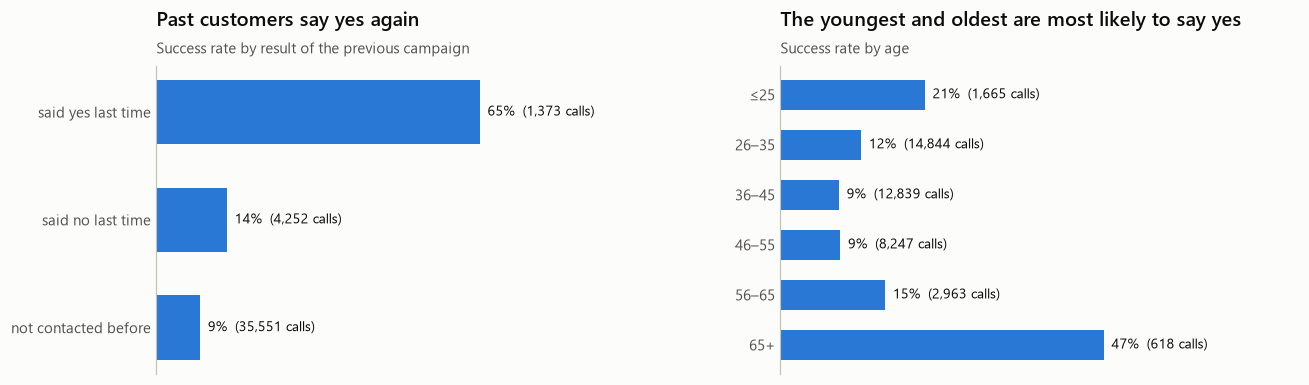

In [7]:
def rate_by(column, order=None):
    table = df.groupby(column, observed=True)["subscribed"].agg(rate="mean", calls="count")
    return table.reindex(order) if order else table.sort_values("rate")

def bar(ax, table, title, sub):
    bars = ax.barh(table.index.astype(str), table["rate"] * 100, color=cs.PRIMARY, height=0.6)
    ax.bar_label(bars, labels=[f"{r:.0%}  ({n:,} calls)" for r, n in zip(table["rate"], table["calls"])],
                 padding=5, fontsize=9)
    ax.xaxis.set_visible(False)
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_xlim(0, table["rate"].max() * 100 * 1.6)
    cs.title(ax, title, sub)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.6))
bar(left, rate_by("poutcome", ["nonexistent", "failure", "success"]).rename(
        index={"nonexistent": "not contacted before", "failure": "said no last time", "success": "said yes last time"}),
    "Past customers say yes again", "Success rate by result of the previous campaign")
bar(right, rate_by("age_band", bm.AGE_LABELS[::-1]),
    "The youngest and oldest are most likely to say yes", "Success rate by age")
fig.tight_layout(w_pad=4)
fig.savefig("images/who_says_yes.png")
plt.show()

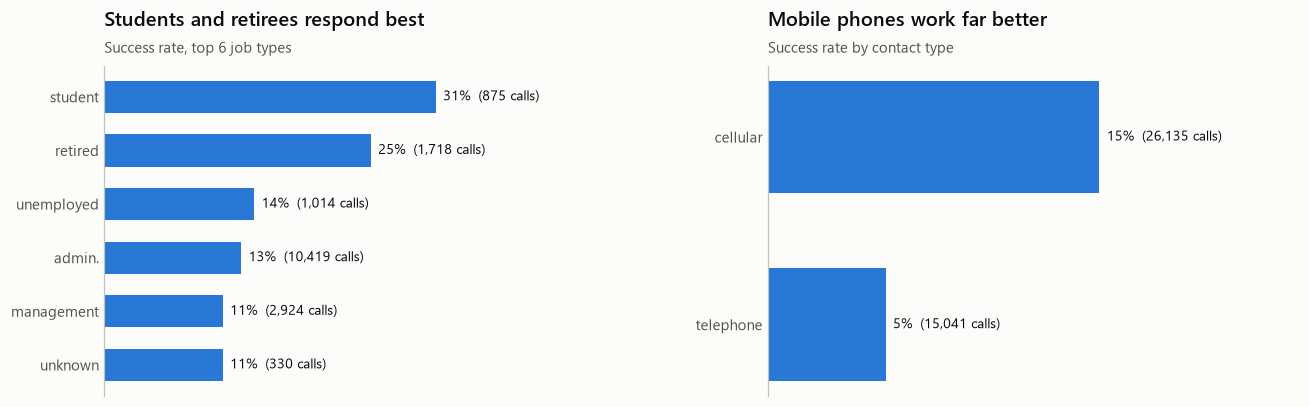

In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8))
bar(left, rate_by("job").tail(6), "Students and retirees respond best", "Success rate, top 6 job types")
bar(right, rate_by("contact"), "Mobile phones work far better", "Success rate by contact type")
fig.tight_layout(w_pad=4)
plt.show()

In [9]:
# nr.employed = number of employed people (thousands), a quarterly indicator of the economy
period = np.where(df["nr.employed"] < 5100, "low employment (crisis years)", "high employment")
df.groupby(period)["subscribed"].agg(rate="mean", calls="count").style.format({"rate": "{:.1%}", "calls": "{:,}"})

,rate,calls
high employment,4.8%,"27,682"
low employment (crisis years),24.5%,"13,494"


**Findings**
- Customers who said **yes in a previous campaign** say yes again **65%** of the time, versus 9% for customers never contacted before. This is the strongest single signal.
- Age has a **U-shape**: under-26s and over-65s respond best. A single straight-line age weight can't capture that, which is why the model uses age bands.
- **Students** and **retirees** respond best; blue-collar workers least.
- Calls to **mobile phones** (cellular) succeed about 3× as often as landline calls.
- When **employment was low** (the crisis years), the success rate was much higher. That's part of the time shift above.

# 4. Statistics: are these differences real?

In [10]:
for column in ["poutcome", "contact", "age_band", "job"]:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df[column], df["subscribed"]))
    print(f"{column:10} chi-square = {chi2:8.1f}   p = {p:.1g}")

poutcome   chi-square =   4230.1   p = 0
contact    chi-square =    862.1   p = 2e-189
age_band   chi-square =   1144.5   p = 3e-245
job        chi-square =    961.7   p = 3e-199


All four are far beyond chance (p ≈ 0). With 41,000 rows even small differences become "significant", so the useful question is **how big** each effect is, which the success rates above answer.

# 5. Models

### Baselines
1. **Call in random order**: precision = the overall success rate.
2. **A simple rule**: call people who said yes before, then students, retirees and the over-65s first, then everyone else.

In [11]:
X_train, y_train = train[bm.FEATURES], train["subscribed"]
X_test, y_test = test[bm.FEATURES], test["subscribed"]
results = {}

def evaluate(name, scores, y_true=y_test):
    order = np.argsort(-np.asarray(scores), kind="stable")
    top = order[: int(len(order) * 0.2)]
    precision = y_true.iloc[top].mean()
    results[name] = {
        "ROC AUC": roc_auc_score(y_true, scores),
        "Precision, top 20%": precision,
        "Lift, top 20%": precision / y_true.mean(),
    }
    return pd.Series(results[name]).round(3)

evaluate("Random order", np.random.default_rng(0).random(len(test)))

ROC AUC               0.505
Precision, top 20%    0.307
Lift, top 20%         0.997
dtype: float64

In [12]:
rule = ((test["poutcome"] == "success") * 3
        + test["job"].isin(["student", "retired"]) * 1
        + (test["age_band"] == "65+") * 1
        + (test["contact"] == "cellular") * 1)
evaluate("Simple rule", rule + np.random.default_rng(0).random(len(test)) * 0.01)   # tiny noise breaks ties

ROC AUC               0.672
Precision, top 20%    0.607
Lift, top 20%         1.968
dtype: float64

### Logistic regression and gradient boosting

**Logistic regression** is the classification version of linear regression: it adds up weighted features and turns the total into a probability between 0 and 1. **Gradient boosting** builds hundreds of small trees. Both are trained on the past and tested on the most recent 20% of calls.

In [13]:
logistic = bm.build_model().fit(X_train, y_train)
evaluate("Logistic regression", logistic.predict_proba(X_test)[:, 1])

ROC AUC               0.748
Precision, top 20%    0.591
Lift, top 20%         1.916
dtype: float64

In [14]:
def build_boosting():
    return make_pipeline(
        ColumnTransformer([
            ("categories", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan), bm.CATEGORICAL),
            ("numbers", "passthrough", bm.NUMERIC),
        ]),
        HistGradientBoostingClassifier(categorical_features=[True] * len(bm.CATEGORICAL) + [False] * len(bm.NUMERIC),
                                       learning_rate=0.05, max_iter=300, random_state=0),
    )

boosting = build_boosting().fit(X_train.astype({c: float for c in bm.NUMERIC}), y_train)
evaluate("Gradient boosting", boosting.predict_proba(X_test.astype({c: float for c in bm.NUMERIC}))[:, 1])

ROC AUC               0.636
Precision, top 20%    0.505
Lift, top 20%         1.639
dtype: float64

In [15]:
comparison = pd.DataFrame(results).T
comparison.style.format({"ROC AUC": "{:.3f}", "Precision, top 20%": "{:.0%}", "Lift, top 20%": "{:.2f}×"})

,ROC AUC,"Precision, top 20%","Lift, top 20%"
Random order,0.505,31%,1.00×
Simple rule,0.672,61%,1.97×
Logistic regression,0.748,59%,1.92×
Gradient boosting,0.636,51%,1.64×


Two surprises:

**1. The simple rule is excellent at the very top.** Its top 20% has a slightly *higher* success rate than the model's. The rule puts everyone who said yes last time first, and they're the most obvious wins. But it only has a handful of score levels, so beyond those customers it can't tell people apart. We'll see what that costs in section 6.

**2. The simpler model beats the "stronger" one.** In topic 16, gradient boosting beat everything. Here it does *worse* than the simple rule. Why?

Trees learn rules like *"if employment > 5,099 then low chance"*. In the test period, employment is lower than **anything in the training data**, and trees can't extrapolate beyond the values they've seen. Logistic regression learns a direction (*"lower employment → higher chance"*), and that direction keeps working in the new conditions.

### What a random split would have told us

In [16]:
X_all = df[bm.FEATURES]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_all, df["subscribed"], test_size=0.2,
                                                        stratify=df["subscribed"], random_state=0)
random_split = pd.DataFrame({
    "Logistic regression": {
        "random split": roc_auc_score(yr_test, bm.build_model().fit(Xr_train, yr_train).predict_proba(Xr_test)[:, 1]),
        "time split (honest)": results["Logistic regression"]["ROC AUC"],
    },
    "Gradient boosting": {
        "random split": roc_auc_score(yr_test, build_boosting().fit(Xr_train.astype({c: float for c in bm.NUMERIC}), yr_train)
                                      .predict_proba(Xr_test.astype({c: float for c in bm.NUMERIC}))[:, 1]),
        "time split (honest)": results["Gradient boosting"]["ROC AUC"],
    },
}).round(3)
random_split

,Logistic regression,Gradient boosting
random split,0.790,0.797
time split (honest),0.748,0.636


With a random split, gradient boosting looks slightly *better* (AUC 0.80), and we'd have deployed it. On the real future it would have been the worst choice. **Test the way the model will be used.**

### Tuning?

We could tune logistic regression's regularisation `C`. But time-series cross-validation *inside* the training period gave an AUC near 0.5 for every value we tried, because the training years themselves contain very different economic periods, so the folds disagree. Tuning made no meaningful difference, so we keep scikit-learn's default. Under dataset shift, even cross-validation struggles.

### How much would leakage have faked?

In [17]:
leaky_features = bm.FEATURES + bm.LEAKY
leaky = make_pipeline(
    ColumnTransformer([
        ("categories", bm.build_model()[0].transformers[0][1], bm.CATEGORICAL),
        ("numbers", bm.build_model()[0].transformers[1][1], bm.NUMERIC + bm.LEAKY),
    ]),
    bm.build_model()[-1],
).fit(train[leaky_features], y_train)
print(f"ROC AUC with duration + campaign: {roc_auc_score(y_test, leaky.predict_proba(test[leaky_features])[:, 1]):.3f}   (fake)")
print(f"ROC AUC without them:             {results['Logistic regression']['ROC AUC']:.3f}   (real)")

ROC AUC with duration + campaign: 0.820   (fake)
ROC AUC without them:             0.748   (real)


# 6. Business value: how many calls should the bank make?

### Cumulative gains

Sort the test customers by the model's score and call them in that order. How many of all the sales do we catch as we go?

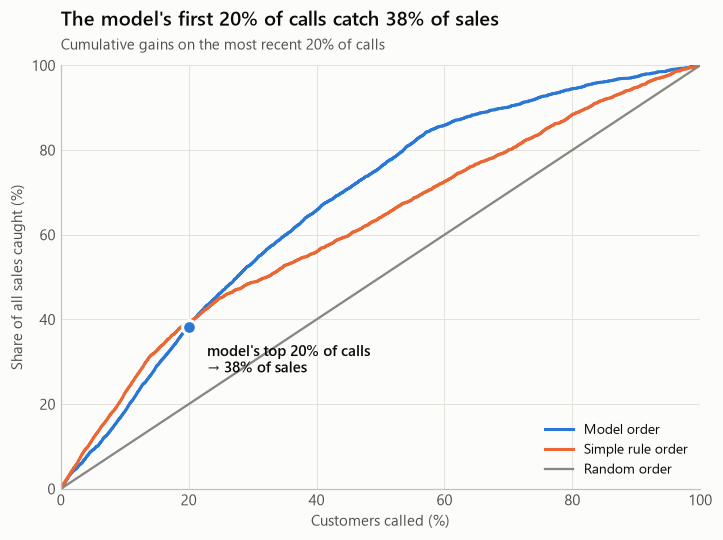

In [18]:
probabilities = logistic.predict_proba(X_test)[:, 1]
COST_PER_CALL, VALUE_PER_SALE = 8, 40   # assumptions in €, adjustable in the app
gains = bm.gains_table(probabilities, y_test, VALUE_PER_SALE, COST_PER_CALL)
rule_gains = bm.gains_table(rule + np.random.default_rng(0).random(len(test)) * 0.01, y_test, VALUE_PER_SALE, COST_PER_CALL)
total_sales = y_test.sum()

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(gains["share_called"] * 100, gains["sales"] / total_sales * 100, color=cs.PRIMARY, label="Model order")
ax.plot(rule_gains["share_called"] * 100, rule_gains["sales"] / total_sales * 100, color=cs.SLOTS[1], label="Simple rule order")
ax.plot([0, 100], [0, 100], color=cs.MUTED, linewidth=1.5, label="Random order")
at20 = gains.iloc[int(len(gains) * 0.2) - 1]
ax.plot(20, at20["sales"] / total_sales * 100, "o", color=cs.PRIMARY, markeredgecolor=cs.SURFACE, markeredgewidth=2, markersize=9)
ax.annotate(f"model's top 20% of calls\n→ {at20['sales'] / total_sales:.0%} of sales", (20, at20["sales"] / total_sales * 100),
            xytext=(12, -30), textcoords="offset points", fontweight="semibold")
ax.set(xlim=(0, 100), ylim=(0, 100), xlabel="Customers called (%)", ylabel="Share of all sales caught (%)")
ax.legend(loc="lower right")
cs.title(ax, f"The model's first 20% of calls catch {at20['sales'] / total_sales:.0%} of sales",
         "Cumulative gains on the most recent 20% of calls")
fig.savefig("images/gains.png")
plt.show()

### Profit

With **assumed** numbers (a call costs **€8** of agent time, a sale is worth **€40**), every extra call is worth making until the chance of success gets too low. Change the assumptions in the app to see how the answer moves.

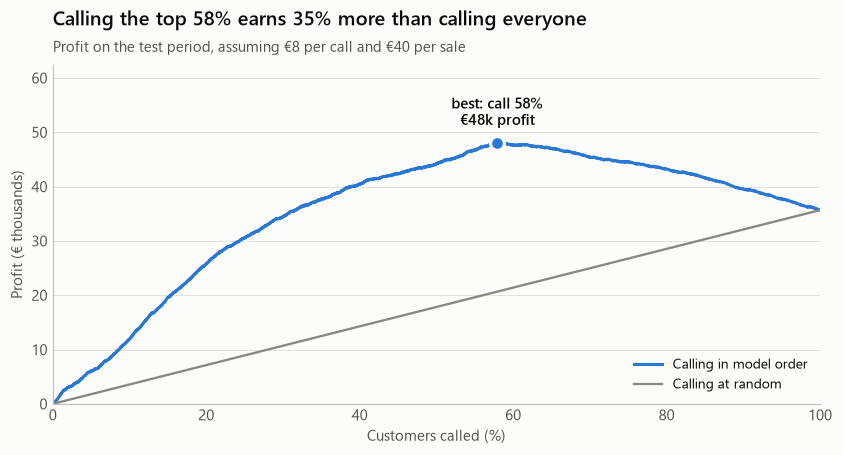

Call everyone:      8,236 calls, 2,539 sales, profit €35,672
Call the top 58%:   4,772 calls, 2,154 sales, profit €47,984
→ 42% fewer calls, 85% of the sales


In [19]:
best = gains.loc[gains["profit"].idxmax()]
call_all = gains.iloc[-1]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(gains["share_called"] * 100, gains["profit"] / 1000, color=cs.PRIMARY, label="Calling in model order")
ax.plot(gains["share_called"] * 100, gains["random_profit"] / 1000, color=cs.MUTED, linewidth=1.5, label="Calling at random")
ax.plot(best["share_called"] * 100, best["profit"] / 1000, "o", color=cs.PRIMARY, markeredgecolor=cs.SURFACE, markeredgewidth=2, markersize=9)
ax.annotate(f"best: call {best['share_called']:.0%}\n€{best['profit'] / 1000:.0f}k profit", (best["share_called"] * 100, best["profit"] / 1000),
            xytext=(0, 12), textcoords="offset points", ha="center", fontweight="semibold")
ax.set(xlim=(0, 100), xlabel="Customers called (%)", ylabel="Profit (€ thousands)")
ax.set_ylim(0, best["profit"] / 1000 * 1.3)
ax.legend(loc="lower right")
cs.only_grid(ax, "y")
cs.title(ax, f"Calling the top {best['share_called']:.0%} earns {best['profit'] / call_all['profit'] - 1:.0%} more than calling everyone",
         f"Profit on the test period, assuming €{COST_PER_CALL} per call and €{VALUE_PER_SALE} per sale")
fig.savefig("images/profit.png")
plt.show()

print(f"Call everyone:      {len(gains):,} calls, {total_sales:,} sales, profit €{call_all['profit']:,.0f}")
print(f"Call the top {best['share_called']:.0%}:   {int(best['calls']):,} calls, {int(best['sales']):,} sales, profit €{best['profit']:,.0f}")
print(f"→ {1 - best['calls'] / len(gains):.0%} fewer calls, {best['sales'] / total_sales:.0%} of the sales")

### Model vs simple rule, at every call volume

In [20]:
volumes = [0.1, 0.2, 0.4, 0.58, 0.8]
table = pd.DataFrame(
    {f"sales if calling top {v:.0%}": [int(rule_gains.iloc[int(len(test) * v) - 1]["sales"]),
                                       int(gains.iloc[int(len(test) * v) - 1]["sales"])]
     for v in volumes},
    index=["Simple rule", "Model"],
)
table["best profit"] = [f"€{rule_gains['profit'].max():,.0f}", f"€{gains['profit'].max():,.0f}"]
table

,sales if calling top 10%,sales if calling top 20%,sales if calling top 40%,sales if calling top 58%,sales if calling top 80%,best profit
Simple rule,572,999,1421,1796,2245,"€37,488"
Model,462,973,1670,2154,2399,"€47,984"


The rule wins for the first ~20% of calls (it puts every past "yes" first), but the model pulls ahead once the bank needs to go deeper, and the profitable decision here is to call over half the list. **A model's value isn't one number; it depends on how the business will use it.** A sensible next step is a hybrid: call past successes first, then follow the model.

# 7. What does the model rely on?

Logistic regression is easy to explain: each feature has a weight. Exponentiated, a weight becomes an **odds ratio**: 2.0 means "doubles the odds of a yes", 0.5 means "halves them".

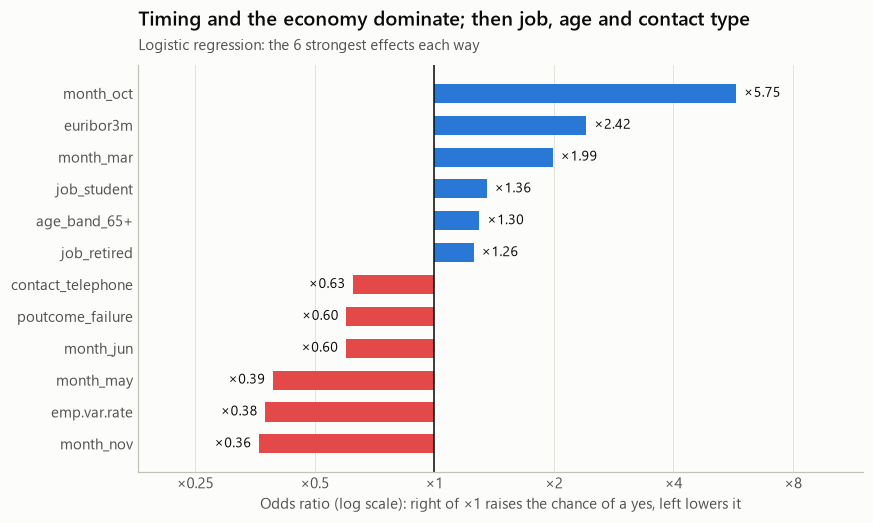

In [21]:
names = logistic[0].get_feature_names_out()
weights = pd.Series(logistic[-1].coef_[0], index=names)
weights.index = (weights.index.str.replace("categories__", "", regex=False)
                              .str.replace("numbers__", "", regex=False))
top = pd.concat([weights.nsmallest(6), weights.nlargest(6)]).sort_values()
odds = np.exp(top)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [cs.SLOTS[0] if w > 0 else cs.SLOTS[7] for w in top]
bars = ax.barh(top.index, odds - 1, left=1, color=colors, height=0.6)
ax.axvline(1, color=cs.INK, linewidth=1)
ax.bar_label(bars, labels=[f"×{o:.2f}" for o in odds], padding=5, fontsize=9)
ax.set_xscale("log")
ticks = [0.25, 0.5, 1, 2, 4, 8]
ax.set_xticks(ticks, [f"×{t:g}" for t in ticks])
ax.minorticks_off()
ax.set_xlim(0.18, 12)   # room for the labels at both ends
ax.set_xlabel("Odds ratio (log scale): right of ×1 raises the chance of a yes, left lowers it")
cs.only_grid(ax, "x")
cs.title(ax, "Timing and the economy dominate; then job, age and contact type", "Logistic regression: the 6 strongest effects each way")
fig.savefig("images/coefficients.png")
plt.show()

> ⚠️ **Read weights with care.**
> - **Month** mostly records *when the bank was calling*. October, March and December calls happened largely in the high-success crisis period, May calls in the low-success early period. So "month" is partly a stand-in for time, not proof that October is a better month to call.
> - The five **economic indicators** move together, so their individual weights can be large and even point in opposite directions (they partly cancel out). Treat them as one group: "the economy".
> - The **customer-level** effects are the most useful for the call list: students, retirees and over-65s raise the odds; landline contact and a failed previous campaign lower them. (A *successful* previous campaign is shared between several related features, `poutcome`, `previous` and `contacted_before`, so it doesn't appear in the top 6 even though it's the strongest signal in the EDA.)

# 8. Fairness and responsible use

The model uses **age** and **job**. They improve targeting, but in many countries financial products are regulated, and targeting by age can be unfair or unlawful (e.g. aggressively selling to older customers). Before real use:
- Check with compliance whether these features may be used.
- Compare who gets called across age groups, and ask whether that's acceptable.
- Never use the score to *deny* a product, only to order calls.

In [22]:
calls = test.assign(called=gains.set_index(pd.Index(np.argsort(-probabilities, kind="stable")))["calls"]
                    .sort_index().le(best["calls"]).to_numpy())
calls.groupby("age_band", observed=True)["called"].mean().reindex(bm.AGE_LABELS).rename("share of customers called").to_frame().style.format("{:.0%}")

,share of customers called
age_band,
≤25,74%
26–35,51%
36–45,46%
46–55,55%
56–65,81%
65+,98%


At the profit-maximising cut-off, the model would call **almost every customer over 65**, but fewer than half of those aged 36–45. Statistically that's "correct" (older customers respond more), but it's exactly the kind of pattern a compliance team should review before any real campaign.

# 9. Save the model

[bank_model.py](bank_model.py) trains the model on the training period and saves it, so the app can show an honest backtest on the most recent calls.

In [23]:
model = bm.train_and_save()
print("saved", bm.MODEL_FILE.relative_to(bm.HERE))

saved models\campaign_model.joblib


# 10. Summary

| | Result |
|---|---|
| **Problem** | Rank customers so the bank calls the most promising first, and decide how many calls are worth making |
| **Data issues** | Hidden missing values (`unknown`, `999`), two leaky columns, and a big **dataset shift** (6% → 31% success) |
| **Strongest signals** | Previous success (65% say yes again), mobile contact, the youngest and oldest customers, the economy |
| **Model** | Logistic regression: AUC 0.75 on the future. Gradient boosting failed to extrapolate (0.64), even though a random split favoured it |
| **Model vs simple rule** | The rule is as good for the first 20% of calls; the model wins beyond that (€48k vs €37k best profit) |
| **Business value** | Top 20% of calls → 38% of sales (1.9× random). With €8/call and €40/sale, calling the top 58% earns about a third more than calling everyone |
| **Responsible use** | Review the use of age and job with compliance; use scores to order calls, never to deny products |

**Next steps:** retrain regularly as the economy changes, monitor the success rate, run an A/B test (topic 14) comparing model-ordered calls with the current approach, and recalibrate the probabilities for the new period.

➡️ Try it: `streamlit run app.py`